# IADS5 · TP integrador — Ortelana Textil
### Actividad 06 · Ensembles: Random Forest y XGBoost

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 06 · Ensembles: Random Forest y XGBoost

**Qué se espera:** Entrená Random Forest (100 árboles) y XGBoost (100 estimadores, learning_rate=0.1, max_depth=3) en la tarea principal. Compará ambos con el árbol individual y visualizá importancias de features.

**Evidencia a entregar:** Tabla comparativa y gráficos de importancias.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
import time

cat_cols = ["Sucursal_ID", "Tela_ID"]          # identificadores: van con one-hot
num_cols = ["Año", "Metros1", "Metros2"]

def crear_pipeline(modelo):
    """One-hot para los identificadores y numéricas sin cambios (los árboles no necesitan escalado)."""
    preprocesador = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", "passthrough", num_cols),
    ], verbose_feature_names_out=False)   # nombres de columnas cortos, p. ej. "Tela_ID_TELA-001"
    return Pipeline([("prep", preprocesador), ("modelo", modelo)])


In [3]:
# 6.1 Random Forest (100 árboles) y XGBoost (100 estimadores, lr=0.1, max_depth=3) contra el árbol individual
arbol = crear_pipeline(DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=RANDOM_STATE))
rf = crear_pipeline(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))
xgb = crear_pipeline(XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                                   random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss"))

# XGBoost necesita las clases como números (B=0, C=1, M=2, S=3)
codificador = LabelEncoder().fit(y_train)
y_train_num = codificador.transform(y_train)

tiempos = {}
inicio = time.perf_counter()
arbol.fit(X_train, y_train)
tiempos["Árbol gini (depth=4)"] = time.perf_counter() - inicio

inicio = time.perf_counter()
rf.fit(X_train, y_train)
tiempos["Random Forest (100)"] = time.perf_counter() - inicio

inicio = time.perf_counter()
xgb.fit(X_train, y_train_num)
tiempos["XGBoost"] = time.perf_counter() - inicio

# Predicciones en train y test (las de XGBoost se vuelven a convertir a letras)
pred_train = {"Árbol gini (depth=4)": arbol.predict(X_train),
              "Random Forest (100)": rf.predict(X_train),
              "XGBoost": codificador.inverse_transform(xgb.predict(X_train))}
pred_test = {"Árbol gini (depth=4)": arbol.predict(X_test),
             "Random Forest (100)": rf.predict(X_test),
             "XGBoost": codificador.inverse_transform(xgb.predict(X_test))}

tabla = pd.DataFrame({
    "F1 macro train": [f1_score(y_train, pred_train[m], average="macro") for m in pred_test],
    "Accuracy test": [accuracy_score(y_test, pred_test[m]) for m in pred_test],
    "F1 macro test": [f1_score(y_test, pred_test[m], average="macro") for m in pred_test],
    "Tiempo de ajuste (s)": [tiempos[m] for m in pred_test],
}, index=list(pred_test))
tabla.round(4)

,F1 macro train,Accuracy test,F1 macro test,Tiempo de ajuste (s)
Árbol gini (depth=4),0.6389,0.6545,0.6460,0.0105
Random Forest (100),1.0000,0.9756,0.9751,0.1716
XGBoost,0.9157,0.8889,0.8877,0.2789


,Árbol gini,Random Forest,XGBoost
Sucursal_ID,0.0100,0.1892,0.2519
Tela_ID,0.0719,0.2704,0.5889
Año,0.0000,0.0333,0.0167
Metros1,0.5486,0.2593,0.0629
Metros2,0.3695,0.2478,0.0795


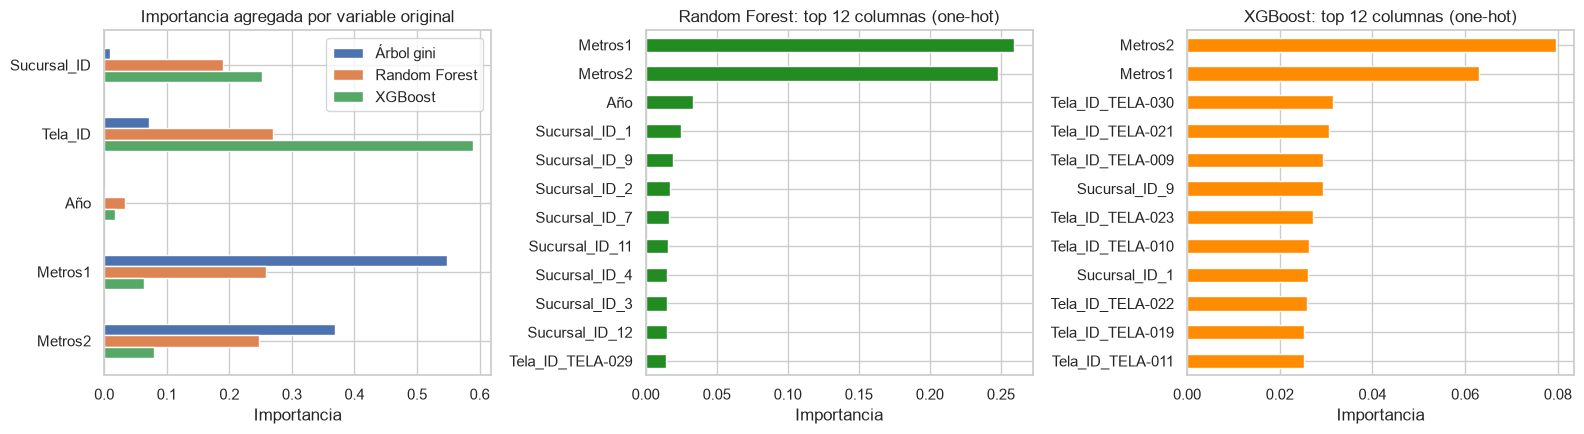

In [4]:
# 6.2 Importancia de cada variable original (se suman sus columnas one-hot)
nombres = rf.named_steps["prep"].get_feature_names_out()
modelos = {"Árbol gini": arbol, "Random Forest": rf, "XGBoost": xgb}

importancias = pd.DataFrame(index=features)
for nombre, modelo in modelos.items():
    imp = pd.Series(modelo.named_steps["modelo"].feature_importances_, index=nombres)
    importancias[nombre] = [imp[imp.index.str.startswith(var)].sum() for var in features]
display(importancias.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
importancias.plot(kind="barh", ax=axes[0])
axes[0].set(title="Importancia agregada por variable original", xlabel="Importancia")
axes[0].invert_yaxis()

# Las 12 columnas (one-hot incluidas) más importantes de cada ensamble
for ax, nombre, color in [(axes[1], "Random Forest", "forestgreen"), (axes[2], "XGBoost", "darkorange")]:
    imp = pd.Series(modelos[nombre].named_steps["modelo"].feature_importances_, index=nombres)
    imp.nlargest(12).sort_values().plot(kind="barh", ax=ax, color=color)
    ax.set(title=f"{nombre}: top 12 columnas (one-hot)", xlabel="Importancia")

plt.tight_layout()
plt.show()

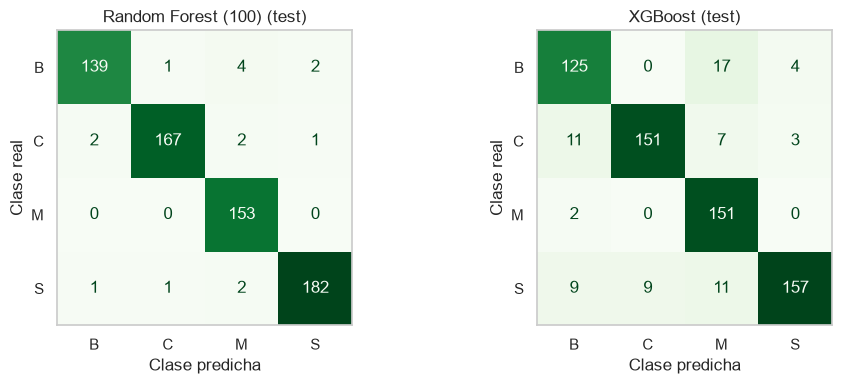

In [5]:
# 6.3 Matrices de confusión de los ensambles (test)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, nombre in zip(axes, ["Random Forest (100)", "XGBoost"]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test[nombre], ax=ax, cmap="Greens", colorbar=False)
    ax.set(title=f"{nombre} (test)", xlabel="Clase predicha", ylabel="Clase real")
    ax.grid(False)
plt.tight_layout()
plt.show()

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Modelos:** entrenamos `RandomForestClassifier(n_estimators=100)` y `XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3)` con los parámetros que pide la consigna y `random_state=42`. Los dos van dentro de un pipeline con one-hot.
- **Etiquetas de XGBoost:** necesita clases 0..3, así que usamos un `LabelEncoder` ajustado solo con train y decodificamos las predicciones para medir.
- **Comparación:** contra los dos árboles de la Actividad 05, con F1 en train y test, tiempo de ajuste e importancias agregadas por variable original.

**Interpretación de los resultados:**
- **Random Forest:** F1 macro en test de **0,975** (accuracy 0,976), muy por encima del árbol (0,646) y de la logística (0,730).
- **XGBoost:** 0,888 en test.
- **Brechas train/test:**
  - RF tiene F1 de train = 1,00, porque los árboles crecen sin límite, pero generaliza bien.
  - XGBoost (0,916 en train contra 0,888 en test) todavía está limitado por `max_depth=3` y 100 rondas con lr 0,1.
- **Importancias:** cambian respecto del árbol individual.
  - En RF, `Tela_ID` (0,27), `Metros1` (0,26) y `Metros2` (0,25) pesan parecido, y `Sucursal_ID` sube a 0,19.
  - En XGBoost dominan `Tela_ID` (0,59) y `Sucursal_ID` (0,25).
  - Los ensambles aprovechan la combinación sucursal + tela. Como el formato es constante para cada par, esa combinación casi determina la clase (ver la Actividad 01).
  - Ninguna variable tiene una importancia cercana a 1 (la mayor es 0,59). La Unidad 3 advierte que una importancia casi total puede indicar data leakage; acá no aparece esa señal, porque ya excluimos el proxy (`Metros3`–`Metros12`).

**Pregunta de análisis:** ¿El ensamble mejora la baseline y el árbol? ¿Qué sacrificios de interpretación o costo computacional observás?
- **Mejora:** sí, y mucho. Contra la baseline, de 0,11 a 0,975 (RF) y 0,888 (XGB); contra el árbol depth 4, de 0,646 a 0,975.
- **Interpretación:** con 100 árboles ya no se puede leer una regla como en la Actividad 05. Solo quedan importancias globales, que no dicen la dirección del efecto y en el one-hot se reparten entre 30 telas y 12 sucursales.
- **Costo computacional:** el ajuste pasa de ~0,01 s (árbol) a ~0,14 s (RF) y ~0,26 s (XGB). Es poco en absoluto, pero entre 15 y 30 veces más. El modelo serializado y la predicción también son más pesados.
- **Riesgo:** parte de la mejora es memorizar pares (Sucursal, Tela) que se repiten entre train y test.

**Limitaciones o mejoras posibles:**
- Los hiperparámetros de XGBoost son los de la consigna, no están ajustados; con más profundidad o más rondas probablemente mejoraría.
- Las importancias por impureza pueden sesgarse; la importancia por permutación sería una alternativa.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]
